# 02 — Variables de qualité et stratégie de prédiction

**Choix retenu (option C) :** la qualité d'une soudure a deux facettes, traitées par deux
modèles de régression séparés :
1. **la résistance**, mesurée par la limite d'élasticité : on commence par elle ;
2. **la ténacité**, mesurée par la résilience Charpy, avec sa température d'essai en
   entrée : on la traitera ensuite.

Ce notebook répond à trois questions :
1. Que mesurent les variables de qualité, et sont-elles redondantes ?
2. Quelles variables de la recette influencent la limite d'élasticité ?
3. Quelle stratégie de prédiction en déduire (entrées, validation, métriques, modèles) ?

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GroupKFold, KFold, cross_val_score

sys.path.insert(0, str(Path.cwd().parent / "src"))
import welddb

sns.set_theme(style="whitegrid", context="notebook")
df = welddb.load()
TARGET = "yield_strength_MPa"

## 1. Les variables représentatives de la qualité

| Variable | Ce qu'elle mesure | Lignes |
|---|---|---|
| Limite d'élasticité (MPa) | contrainte à partir de laquelle la déformation devient permanente | 780 |
| Résistance à la traction (MPa) | contrainte maximale avant rupture | 738 |
| Allongement, striction (%) | ductilité : capacité à se déformer avant de rompre | ~700 |
| Résilience Charpy (J) | énergie absorbée lors d'un choc, à une température donnée | 879 |
| Dureté, FATT, microstructure | trop peu renseignées pour être utilisées | < 140 |

Une bonne soudure doit être **résistante** (ne pas se déformer sous la charge) **et tenace**
(ne pas casser brutalement sous un choc, en particulier au froid).

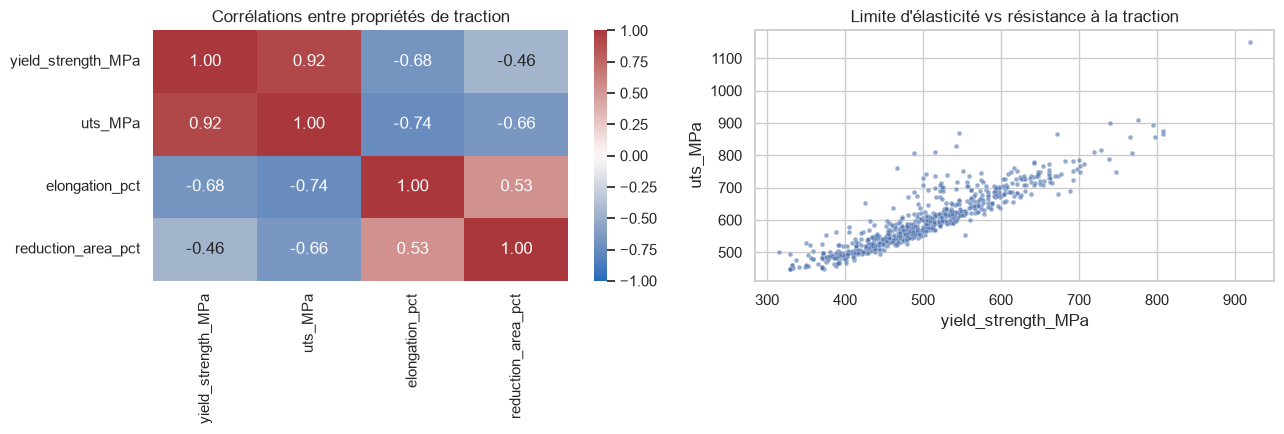

In [2]:
mech = ["yield_strength_MPa", "uts_MPa", "elongation_pct", "reduction_area_pct"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(df[mech].corr(), annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Corrélations entre propriétés de traction")
sns.scatterplot(data=df, x="yield_strength_MPa", y="uts_MPa", s=12, alpha=0.6, ax=axes[1])
axes[1].set_title("Limite d'élasticité vs résistance à la traction")
plt.tight_layout();

- Limite d'élasticité et résistance à la traction sont corrélées à 0,92 : elles portent
  presque la même information. On garde **la limite d'élasticité**, la grandeur utilisée
  pour dimensionner les structures.
- La ductilité (allongement, striction) diminue quand la résistance augmente : c'est le
  compromis classique résistance / ductilité.
- La résilience Charpy est une information différente (le comportement au choc). Elle n'est
  mesurée en même temps que la limite d'élasticité que sur 144 lignes, d'où le choix de
  **deux modèles séparés** plutôt qu'une étiquette combinée.

## 2. La cible : limite d'élasticité

### Effet du traitement thermique après soudage

Les températures de traitement ne sont pas toutes de même nature. Entre 200 et 250 °C,
il s'agit d'un **dégazage de l'hydrogène** (les lignes `aw` d'Evans, « brut de soudage »,
sont à 250 °C pendant 14 h). Au-dessus de 400 °C (en pratique de 550 à 760 °C), c'est un
**revenu de détensionnement**, qui modifie la microstructure.

780 lignes étiquetées, 42 publications


,count,mean,std,min,25%,50%,75%,max
heat_treatment,,,,,,,,
aucun,201.0,507.0,82.0,349.0,456.0,504.0,547.0,808.0
dégazage (< 400 °C),287.0,493.0,73.0,337.0,442.0,481.0,526.0,808.0
inconnu,13.0,638.0,95.0,431.0,588.0,630.0,715.0,784.0
revenu (≥ 400 °C),279.0,520.0,111.0,315.0,432.0,515.0,594.0,920.0


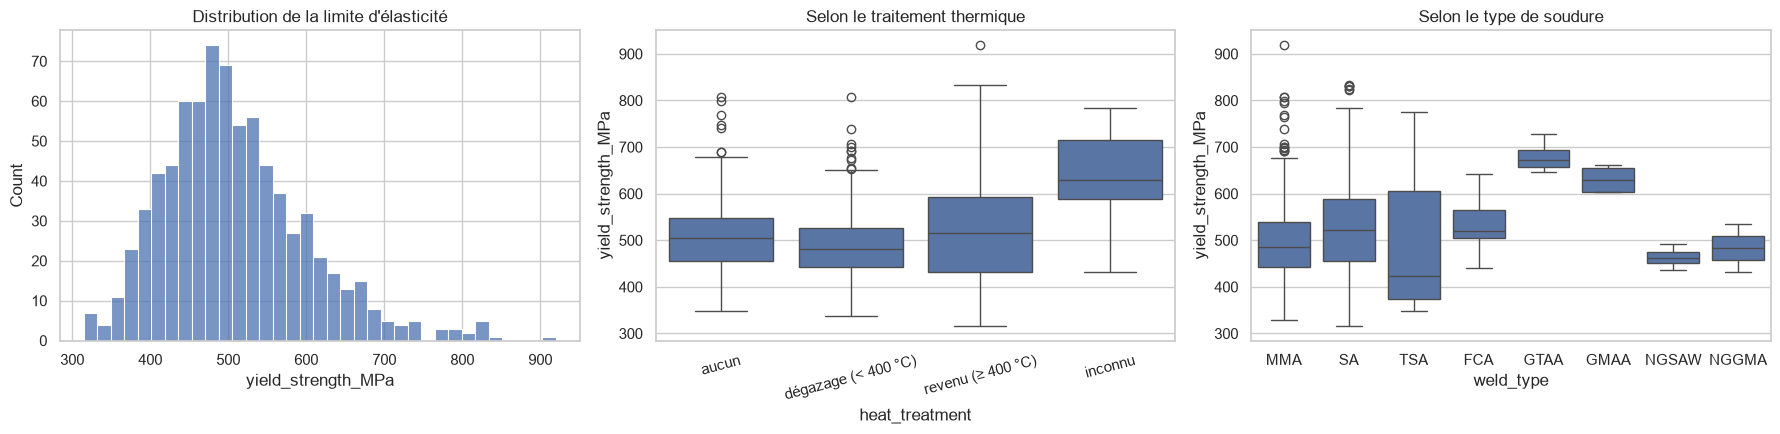

In [3]:
def heat_treatment_kind(t):
    if pd.isna(t):
        return "inconnu"
    if t == 0:
        return "aucun"
    if t < 400:
        return "dégazage (< 400 °C)"
    return "revenu (≥ 400 °C)"

df["heat_treatment"] = df["pwht_temp_C"].map(heat_treatment_kind)
labelled = df[df[TARGET].notna()].reset_index(drop=True)
print(f"{len(labelled)} lignes étiquetées, {labelled['publication'].nunique()} publications")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.histplot(labelled[TARGET], bins=35, ax=axes[0]).set_title("Distribution de la limite d'élasticité")
order = ["aucun", "dégazage (< 400 °C)", "revenu (≥ 400 °C)", "inconnu"]
sns.boxplot(data=labelled, x="heat_treatment", y=TARGET, order=order, ax=axes[1])
axes[1].set_title("Selon le traitement thermique"); axes[1].tick_params(axis="x", rotation=15)
sns.boxplot(data=labelled, x="weld_type", y=TARGET, ax=axes[2],
            order=labelled["weld_type"].value_counts().index)
axes[2].set_title("Selon le type de soudure")
plt.tight_layout()
labelled.groupby("heat_treatment")[TARGET].describe().round(0)

- La limite d'élasticité est centrée autour de 500 MPa, avec une queue vers les valeurs
  élevées (aciers alliés).
- Le traitement thermique change peu la médiane, mais le revenu élargit beaucoup la
  dispersion : son effet dépend de la composition (interaction), ce qu'un modèle linéaire
  simple captera mal.
- Les types de soudure rares (GTAA, GMAA, NGSAW…) ont moins de 10 lignes : on ne peut rien
  conclure pour eux, et il faudra peut-être les regrouper.

## 3. Quelles variables influencent la limite d'élasticité ?

### 3.1 Taux de remplissage sur les lignes étiquetées

In [4]:
inputs_num = welddb.COMPOSITION + welddb.PROCESS_NUM
fill = (100 * labelled[inputs_num + welddb.PROCESS_CAT].notna().mean()).round(0)
fill.to_frame("% renseigné (lignes étiquetées)").T

,C,Si,Mn,S,P,Ni,Cr,Mo,V,Cu,...,Sb_ppm,current_A,voltage_V,heat_input_kJmm,interpass_temp_C,pwht_temp_C,pwht_time_h,ac_dc,polarity,weld_type
% renseigné (lignes étiquetées),100.0,100.0,100.0,99.0,99.0,50.0,51.0,51.0,58.0,42.0,...,11.0,86.0,86.0,100.0,100.0,98.0,98.0,86.0,93.0,100.0


Co, W, Sn, As et Sb sont renseignés sur moins de 20 % des lignes étiquetées : on les
écarte. Pour les éléments d'alliage (Ni, Cr, Mo, V, Cu), environ la moitié des lignes est
manquante.

### 3.2 Corrélations simples (Spearman)

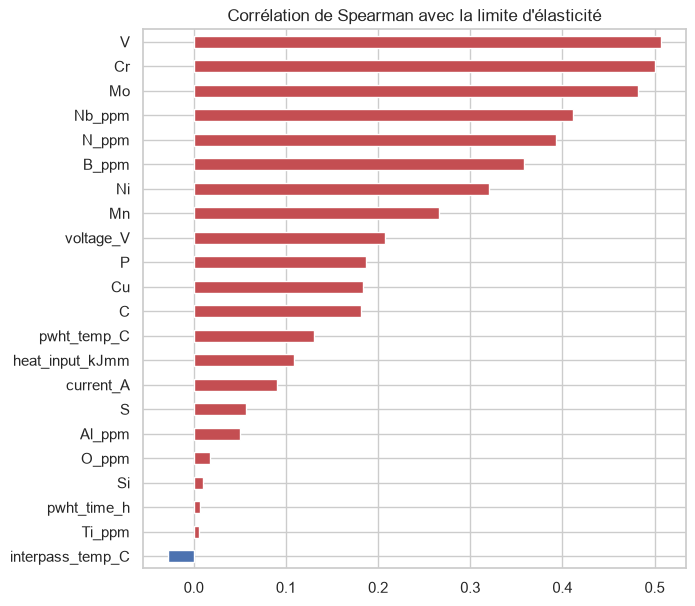

In [5]:
candidates = [c for c in inputs_num if fill[c] >= 20]
spearman = labelled[candidates].corrwith(labelled[TARGET], method="spearman").sort_values()
ax = spearman.plot.barh(figsize=(7, 7), color=np.where(spearman > 0, "C3", "C0"))
ax.set_title("Corrélation de Spearman avec la limite d'élasticité");

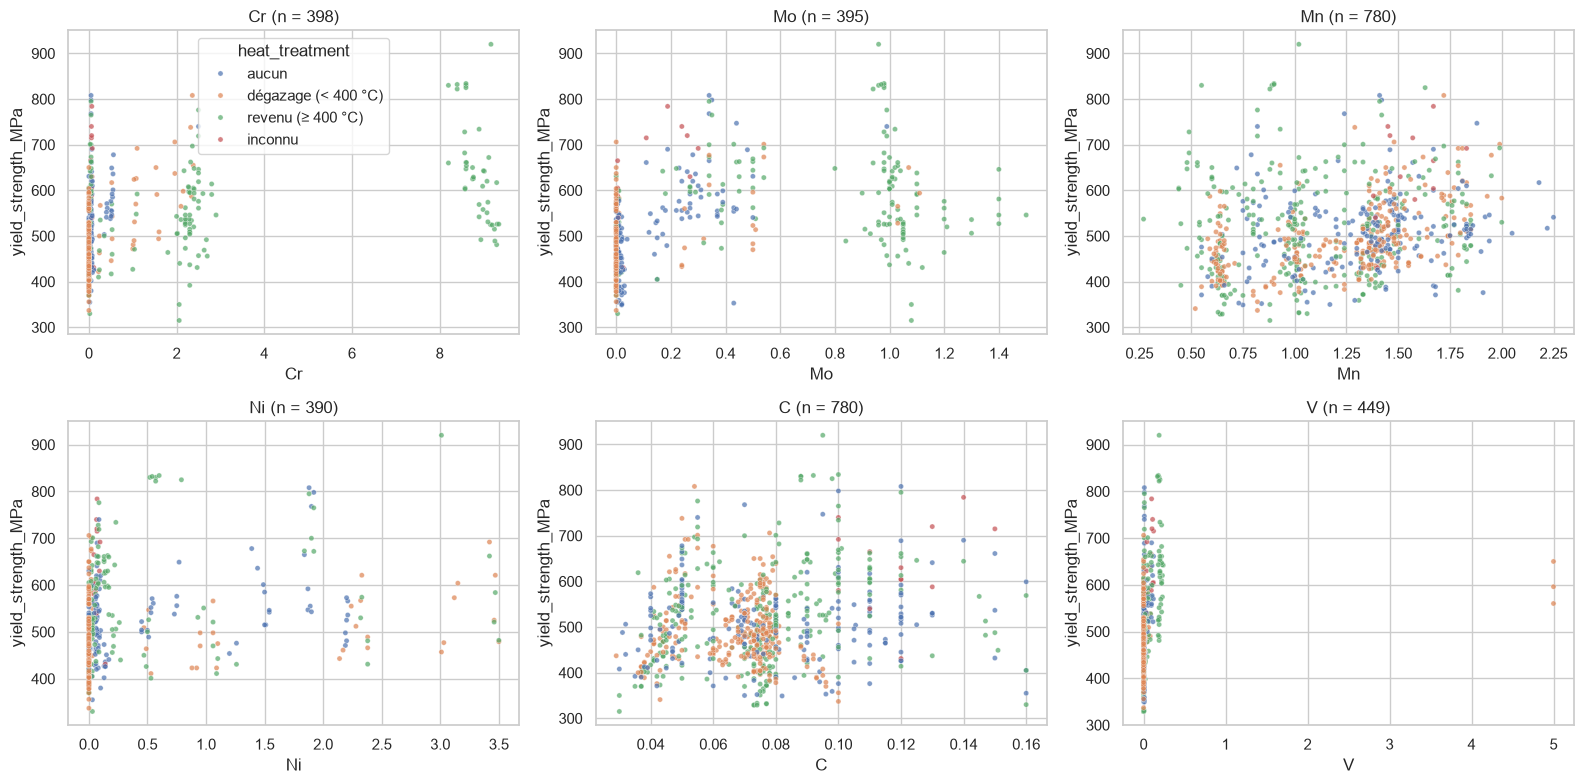

In [6]:
top = ["Cr", "Mo", "Mn", "Ni", "C", "V"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.flat, top):
    sns.scatterplot(data=labelled, x=c, y=TARGET, hue="heat_treatment", hue_order=order,
                    s=14, alpha=0.7, ax=ax, legend=(c == top[0]))
    ax.set_title(f"{c} (n = {labelled[c].notna().sum()})")
plt.tight_layout();

### 3.3 Importance des variables avec un modèle non linéaire

La corrélation ne voit que des relations monotones, une variable à la fois. Pour avoir une
première idée des interactions, on entraîne un gradient boosting
(`HistGradientBoostingRegressor`, qui accepte les valeurs manquantes sans imputation) et on
mesure l'**importance par permutation** : de combien l'erreur augmente si on mélange
aléatoirement une variable. Le calcul est fait sur des données de test jamais vues
(validation croisée groupée, voir section 4).

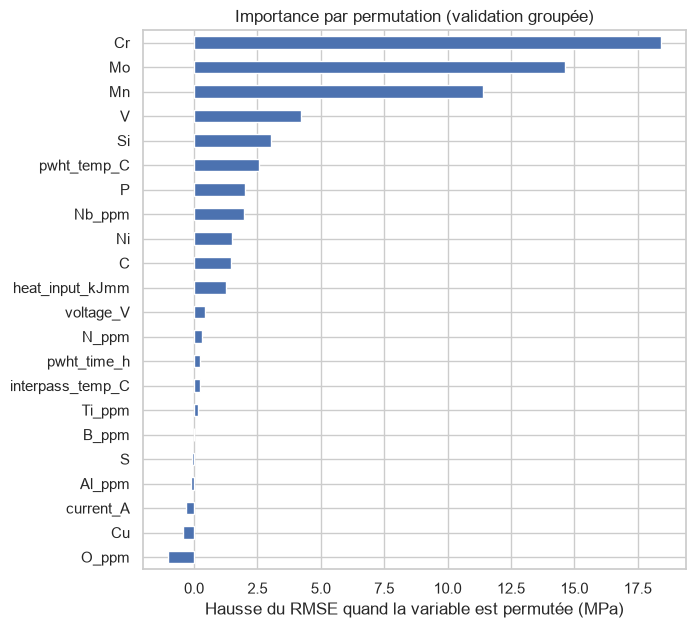

In [7]:
X = labelled[candidates]
y = labelled[TARGET]
groups = labelled["publication"]
model = HistGradientBoostingRegressor(random_state=0)

importances = []
for train, test in GroupKFold(n_splits=5).split(X, y, groups):
    model.fit(X.iloc[train], y.iloc[train])
    r = permutation_importance(model, X.iloc[test], y.iloc[test], n_repeats=10,
                               random_state=0, scoring="neg_root_mean_squared_error")
    importances.append(r.importances_mean)
importance = pd.Series(np.mean(importances, axis=0), index=candidates).sort_values()

ax = importance.plot.barh(figsize=(7, 7))
ax.set_xlabel("Hausse du RMSE quand la variable est permutée (MPa)")
ax.set_title("Importance par permutation (validation groupée)");

**Lecture.** Les éléments d'alliage **Cr, Mo, Mn**, puis V, Si et la température de
traitement thermique, dominent : ils durcissent
le métal, par solution solide et en favorisant des microstructures plus fines. Cela
correspond à la métallurgie connue des soudures. Les paramètres de procédé (apport de
chaleur, traitement thermique) jouent un rôle plus faible dans ce modèle.

Précautions :
- les variables corrélées entre elles (Cr et Mo varient souvent ensemble) se partagent
  l'importance ;
- les aciers riches en Cr/Mo viennent de quelques publications seulement : une partie de
  l'effet peut être un effet « publication ».

On ne retire donc pas de variable à ce stade, sauf celles qui sont presque vides.

## 4. L'effet « publication » et le choix de la validation

Les lignes d'une même publication se ressemblent beaucoup (même laboratoire, même
protocole, souvent la même soudure mesurée plusieurs fois). Quelle part de la variance de
la cible est expliquée simplement en connaissant la publication ?

In [8]:
pub_mean = labelled.groupby("publication")[TARGET].transform("mean")
r2_pub = 1 - ((y - pub_mean) ** 2).sum() / ((y - y.mean()) ** 2).sum()
# R² ajusté : corrige le nombre de moyennes estimées (une par publication)
n, k = len(y), labelled["publication"].nunique()
r2_pub_adj = 1 - (1 - r2_pub) * (n - 1) / (n - k)
print(f"R² obtenu en prédisant la moyenne de la publication : {r2_pub:.2f} (ajusté : {r2_pub_adj:.2f})")

R² obtenu en prédisant la moyenne de la publication : 0.47 (ajusté : 0.44)


Près de la moitié de la variance s'explique par la publication. Ce R² est calculé sur les
données mêmes qui servent à estimer les moyennes : le R² ajusté, qui tient compte des
42 moyennes estimées, confirme l'ordre de grandeur. Si on mélange les lignes au
hasard pour la validation croisée, le modèle voit en entraînement des soudures quasi
identiques à celles du test, et son score est trop optimiste. Comparons :

In [9]:
results = {}
for name, cv, g in [("KFold aléatoire", KFold(5, shuffle=True, random_state=0), None),
                    ("GroupKFold par publication", GroupKFold(5), groups)]:
    scores = -cross_val_score(model, X, y, cv=cv, groups=g, scoring="neg_root_mean_squared_error")
    results[name] = {"RMSE moyen (MPa)": scores.mean(), "écart-type": scores.std(ddof=1)}
scores = -cross_val_score(DummyRegressor(), X, y, cv=GroupKFold(5), groups=groups,
                          scoring="neg_root_mean_squared_error")
results["Référence : prédire la moyenne (GroupKFold)"] = {"RMSE moyen (MPa)": scores.mean(), "écart-type": scores.std(ddof=1)}
pd.DataFrame(results).T.round(1)

,RMSE moyen (MPa),écart-type
KFold aléatoire,36.4,9.0
GroupKFold par publication,70.3,14.4
Référence : prédire la moyenne (GroupKFold),92.6,16.1


**L'erreur double** quand on évalue sur des publications jamais vues. C'est l'estimation
honnête de la question qui nous intéresse : *prédire la qualité d'une nouvelle soudure,
faite dans de nouvelles conditions*. On retient donc la **validation croisée groupée par
publication**.

## 5. Les lignes non étiquetées (pour le semi-supervisé)

In [10]:
unlabelled = df[df[TARGET].isna()]
key = welddb.COMPOSITION + welddb.PROCESS_NUM + welddb.PROCESS_CAT
labelled_keys = set(map(tuple, labelled[key].astype(str).values))
same_recipe = unlabelled[key].astype(str).apply(tuple, axis=1).isin(labelled_keys)

print(f"Lignes sans limite d'élasticité : {len(unlabelled)}")
print(f"  dont lignes Charpy : {unlabelled['charpy_toughness_J'].notna().sum()}")
print(f"  dont recette identique à une ligne étiquetée : {same_recipe.sum()}")
print(f"  lignes dont la recette est absente des lignes étiquetées : {(~same_recipe).sum()}")

Lignes sans limite d'élasticité : 872
  dont lignes Charpy : 735
  dont recette identique à une ligne étiquetée : 489
  lignes dont la recette est absente des lignes étiquetées : 383


Beaucoup de lignes « non étiquetées » sont en fait **la même soudure** qu'une ligne
étiquetée, mesurée cette fois en Charpy. Pour le semi-supervisé, il faudra :
- ne garder que les recettes distinctes ;
- vérifier que ces lignes ne contiennent pas des publications du jeu de test (sinon fuite
  d'information).

## 6. Stratégie retenue

| Élément | Choix | Justification |
|---|---|---|
| **Tâche** | Régression | Garder l'information fine (400 MPa ≠ 900 MPa), pas de seuil arbitraire |
| **Cible 1** | Limite d'élasticité (780 lignes) | Grandeur de dimensionnement ; la résistance à la traction est redondante (r = 0,92) |
| **Cible 2 (ensuite)** | Résilience Charpy, température d'essai en entrée | Résistance au choc / au froid, information complémentaire |
| **Entrées** | Composition (sans Co, W, Sn, As, Sb), courant, tension, apport de chaleur, température entre passes, traitement thermique (température, durée), type de soudure, AC/DC, polarité | Recette connue *avant* de souder ; variables presque vides écartées |
| **Pré-traitement** | Imputation (0 pour les éléments d'alliage non ajoutés, médiane pour les autres variables), one-hot pour les catégories, standardisation | Dans un `Pipeline`, pour éviter les fuites d'information |
| **Validation** | `GroupKFold` par publication (5 plis), hyperparamètres réglés en validation imbriquée | Le KFold aléatoire divise l'erreur par deux de façon trompeuse |
| **Métriques** | RMSE (principale, en MPa), MAE, R² | RMSE et MAE dans l'unité physique ; R² pour comparer à la référence |
| **Modèles** | Référence (moyenne), régression linéaire, k-NN, SVR, forêt aléatoire (méthodes du cours), gradient boosting | Du plus simple et interprétable au plus flexible |
| **Semi-supervisé** | Self-training, puis régularisation de variété (notebook 03) | ~870 lignes sans limite d'élasticité, dont beaucoup de recettes déjà étiquetées (section 5) |

**Prochaine étape :** le notebook 03, avec le pré-traitement dans un pipeline et la
comparaison des modèles supervisés.